In [1]:
#Importing the necessary libries for the regression
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
np.random.seed(42)

In [2]:
students =pd.read_csv("students.csv")
students.head()

,hours_studied,exam_score
0,4.4,56.7
1,9.6,85.8
2,7.6,76.0
3,6.4,58.4
4,2.4,43.3


In [3]:
students.tail()

,hours_studied,exam_score
95,5.4,58.6
96,5.7,63.8
97,4.8,60.8
98,1.2,38.8
99,2.0,46.0


In [4]:
#data inspection.
print(students.shape)
print(students.isnull().sum())
students.describe()

(100, 2)
hours_studied    0
exam_score       0
dtype: int64


,hours_studied,exam_score
count,100.000000,100.000000
mean,5.233000,61.381000
std,2.681438,16.025168
min,1.000000,33.800000
25%,2.775000,47.575000
50%,5.150000,59.200000
75%,7.600000,75.525000
max,9.900000,93.200000


In [5]:
students

,hours_studied,exam_score
0,4.4,56.7
1,9.6,85.8
2,7.6,76.0
3,6.4,58.4
4,2.4,43.3
...,...,...
95,5.4,58.6
96,5.7,63.8
97,4.8,60.8
98,1.2,38.8


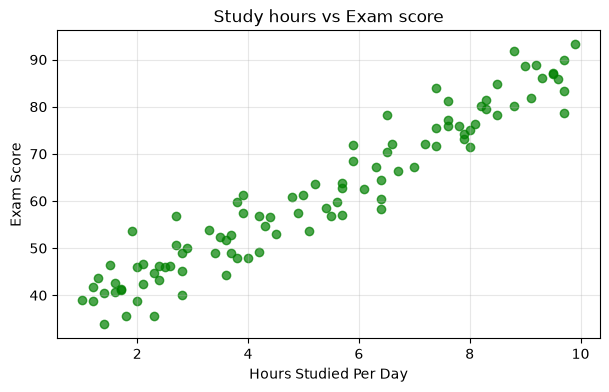

In [6]:
plt.figure(figsize=(7,4))
plt.scatter(students["hours_studied"], students["exam_score"], color="green", alpha=0.7)
plt.xlabel("Hours Studied Per Day")
plt.ylabel("Exam Score")
plt.title("Study hours vs Exam score")
plt.grid(alpha=0.3)
plt.show()

In [7]:
X = students[["hours_studied"]]
y = students["exam_score"]

print("X shape:",X.shape)
print("y shape:", y.shape)

X shape: (100, 1)
y shape: (100,)


In [8]:
#train/test split
#Training: 80%
#Testing: 20%
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training rows:", X_train.shape[0])
print("Testing rows: ", X_test.shape[0])

Training rows: 80
Testing rows:  20


In [9]:
#Training the Linear Model
model= LinearRegression()
model.fit(X_train, y_train)
print("Intercept:  ", round(model.intercept_, 2))
print("Coefficient:", round(model.coef_[0], 2))

Intercept:   30.99
Coefficient: 5.77


In [10]:
#Make prediction using the test data set
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Hours": X_test["hours_studied"].values,
    "Actual score": y_test.values,
    "Predicted score": y_pred.round(),
}
)
results["Difference"] = (results["Actual score"] - results ["Predicted score"]).round(1)
results.head(10)

,Hours,Actual score,Predicted score,Difference
0,1.6,42.7,40.0,2.7
1,9.1,81.8,83.0,-1.2
2,8.0,71.5,77.0,-5.5
3,7.0,67.2,71.0,-3.8
4,3.3,53.9,50.0,3.9
5,5.0,61.3,60.0,1.3
6,3.6,51.8,52.0,-0.2
7,8.8,91.9,82.0,9.9
8,1.2,41.7,38.0,3.7
9,4.4,56.7,56.0,0.7


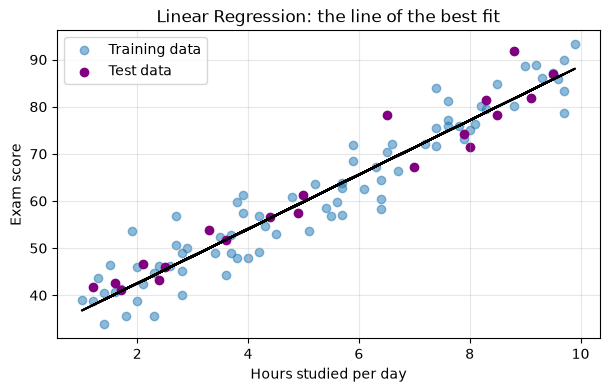

In [11]:
plt.figure(figsize=(7, 4))
plt.scatter(X_train, y_train, alpha=0.5, label="Training data")
plt.scatter(X_test, y_test, color="purple", label= "Test data")

plt.plot(X_train,model.predict(X_train), color="black")
plt.xlabel("Hours studied per day")
plt.ylabel("Exam score")
plt.title("Linear Regression: the line of the best fit")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [12]:
#predict new student
new_student = pd.DataFrame({"hours_studied": [6.8]})
predicted = model.predict(new_student)
print(f"A student who studies 6.8 hours is predicted to score about {predicted[0]:.1f}")

A student who studies 6.8 hours is predicted to score about 70.2
